In [1]:
import numpy as np
import pandas as pd

gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')
local_metrics = np.sum(gene_level_local_metrics.set_index('gene')>2.5, axis=0)/gene_level_local_metrics.shape[0]
global_metrics = np.sum(gene_level_global_metrics.set_index('gene')>2.5, axis=0)/gene_level_global_metrics.shape[0]
local_metrics = local_metrics.reset_index()
global_metrics = global_metrics.reset_index()
prior_z_score = (gene_level_local_metrics.set_index('gene').mean(axis=1)+gene_level_global_metrics.set_index('gene').mean(axis=1))/2
prior_intrinsic_scores = (gene_level_local_metrics.set_index('gene')+gene_level_global_metrics.set_index('gene'))/2

In [2]:
import pandas as pd
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential', 'RPE1_Southard']
for analysis_target in analysis_targets: 
    gene_level_local_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_global_overlap_allpair.csv').set_index('gene')

import numpy as np

plot_df_local = []
plot_df_global = []
for analysis_target in analysis_targets: #,'RPE1_Southard']:
    local_metrics = np.sum(gene_level_local_metrics[analysis_target]>2.5, axis=0)/gene_level_local_metrics[analysis_target].shape[0]
    global_metrics = np.sum(gene_level_global_metrics[analysis_target]>2.5, axis=0)/gene_level_global_metrics[analysis_target].shape[0]
    plot_df_local.append(local_metrics)
    plot_df_global.append(global_metrics)

plot_df_local = pd.concat(plot_df_local, axis=1)
plot_df_local.columns=analysis_targets
plot_df_global = pd.concat(plot_df_global, axis=1)
plot_df_global.columns=analysis_targets

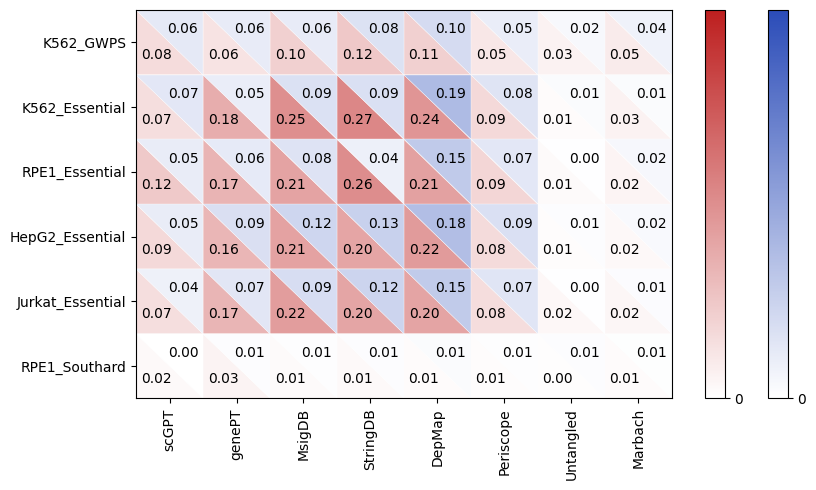

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

from matplotlib.colors import LinearSegmentedColormap

# Define colors as hex codes
colors = ['#FFFFFF', "#BD1F1F"] 
cmap_name = 'white_to_red'
cmap_reds = LinearSegmentedColormap.from_list(cmap_name, colors)

colors = ['#FFFFFF', "#2B4CB8"] 
cmap_name = 'white_to_blue'
cmap_blues = LinearSegmentedColormap.from_list(cmap_name, colors)

plt.figure(figsize=(9, 5))
M = 8
N = 6
x = np.arange(M + 1)
y = np.arange(N + 1)
xs, ys = np.meshgrid(x, y)

plot_df_local = plot_df_local.T[['scGPT','genePT','MsigDB','StringDB','DepMap','Periscope','Untangled','Marbach']].T
plot_df_global = plot_df_global.T[['scGPT','genePT','MsigDB','StringDB','DepMap','Periscope','Untangled','Marbach']].T

triangles1 = [(i + (N-j-1)*(M+1), i+1 + (N-j-1)*(M+1), i + ((N-j-1)+1)*(M+1)) for j in range(N) for i in range(M)]
triangles2 = [(i+1 + (N-j-1)*(M+1), i+1 + ((N-j-1)+1)*(M+1), i + ((N-j-1)+1)*(M+1)) for j in range(N) for i in range(M)]
triang1 = Triangulation(xs.ravel(), ys.ravel(), triangles1)
triang2 = Triangulation(xs.ravel(), ys.ravel(), triangles2)
img1 = plt.tripcolor(triang1, plot_df_local.T.values.flatten(), cmap=cmap_reds, vmax=0.5, vmin=0, edgecolors='white')
img2 = plt.tripcolor(triang2, plot_df_global.T.values.flatten(), cmap=cmap_blues, vmax=0.5, vmin=0, edgecolors='white')

for val, dir in zip([plot_df_local.T.values.flatten(), plot_df_global.T.values.flatten()], [(-1,-1), (1,1)]):
    for i in range(M):
        for j in range(N):
            v = val[i+(N-j-1)*M]
            plt.text(i +0.5 + 0.2 * dir[1], j + 0.5 + 0.2 * dir[0], f'{v:.2f}', color='black', ha='center', va='center')

plt.colorbar(img2, ticks=range(10), pad=-0.05)
plt.colorbar(img1, ticks=range(10))
plt.xlim(x[0], x[-1])
plt.ylim(y[0], y[-1])
plt.xticks(x[:-1]+0.5, rotation=90, labels=plot_df_local.index.tolist())
plt.yticks(y[:-1]+0.5, labels=plot_df_local.columns.tolist()[::-1])
plt.tight_layout()
#plt.savefig('../figure_out/Fig.3C_1.pdf')

### mRNA

In [4]:
import pandas as pd
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential','RPE1_Southard']
for perturb_seq_name in analysis_targets: 
    gene_level_local_metrics[perturb_seq_name] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{perturb_seq_name}_mrnaspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[perturb_seq_name] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{perturb_seq_name}_mrnaspace_gene_global_overlap_allpair.csv').set_index('gene')

import numpy as np

plot_df_local = []
plot_df_global = []
for analysis_target in analysis_targets: #,'RPE1_Southard']:
    local_metrics = np.sum(gene_level_local_metrics[analysis_target]>2.5, axis=0)/gene_level_local_metrics[analysis_target].shape[0]
    global_metrics = np.sum(gene_level_global_metrics[analysis_target]>2.5, axis=0)/gene_level_global_metrics[analysis_target].shape[0]
    local_metrics = local_metrics
    global_metrics = global_metrics
    plot_df_local.append(local_metrics)
    plot_df_global.append(global_metrics)

plot_df_local = pd.concat(plot_df_local, axis=1)
plot_df_local.columns=analysis_targets
plot_df_global = pd.concat(plot_df_global, axis=1)
plot_df_global.columns=analysis_targets

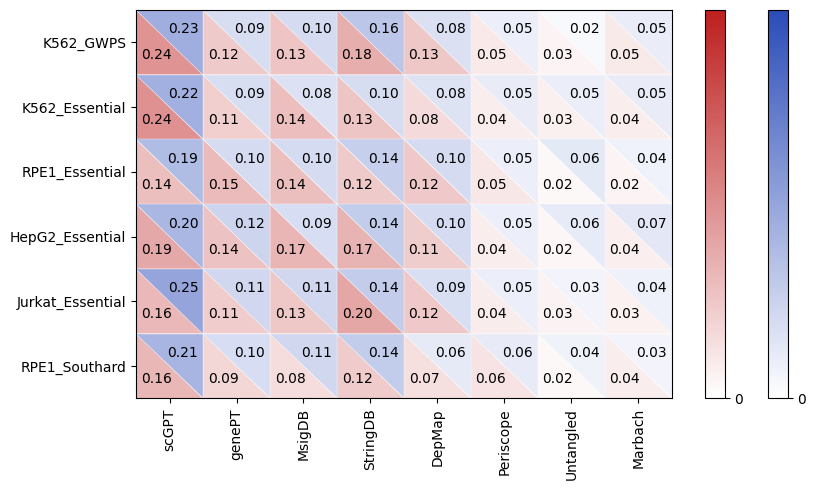

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

plt.figure(figsize=(9, 5))
M = 8
N = 6
x = np.arange(M + 1)
y = np.arange(N + 1)
xs, ys = np.meshgrid(x, y)


plot_df_local = plot_df_local.T[['scGPT','genePT','MsigDB','StringDB','DepMap','Periscope','Untangled','Marbach']].T
plot_df_global = plot_df_global.T[['scGPT','genePT','MsigDB','StringDB','DepMap','Periscope','Untangled','Marbach']].T

triangles1 = [(i + (N-j-1)*(M+1), i+1 + (N-j-1)*(M+1), i + ((N-j-1)+1)*(M+1)) for j in range(N) for i in range(M)]
triangles2 = [(i+1 + (N-j-1)*(M+1), i+1 + ((N-j-1)+1)*(M+1), i + ((N-j-1)+1)*(M+1)) for j in range(N) for i in range(M)]
triang1 = Triangulation(xs.ravel(), ys.ravel(), triangles1)
triang2 = Triangulation(xs.ravel(), ys.ravel(), triangles2)
img1 = plt.tripcolor(triang1, plot_df_local.T.values.flatten(), cmap=cmap_reds, vmax=0.5, vmin=0, edgecolors='white')
img2 = plt.tripcolor(triang2, plot_df_global.T.values.flatten(), cmap=cmap_blues, vmax=0.5, vmin=0, edgecolors='white')

for val, dir in zip([plot_df_local.T.values.flatten(), plot_df_global.T.values.flatten()], [(-1,-1), (1,1)]):
    for i in range(M):
        for j in range(N):
            v = val[i+(N-j-1)*M]
            plt.text(i +0.5 + 0.2 * dir[1], j + 0.5 + 0.2 * dir[0], f'{v:.2f}', color='black', ha='center', va='center')

plt.colorbar(img2, ticks=range(10), pad=-0.05)
plt.colorbar(img1, ticks=range(10))
plt.xlim(x[0], x[-1])
plt.ylim(y[0], y[-1])
plt.xticks(x[:-1]+0.5, rotation=90, labels=plot_df_local.index.tolist())
plt.yticks(y[:-1]+0.5, labels=plot_df_local.columns.tolist()[::-1])
plt.tight_layout()

#plt.savefig('../figure_out/Fig.3C_2.pdf')